<a href="https://colab.research.google.com/github/nikabienkowska-svg/Praca-projektowa-II-Modelowanie-trajektorii-uczenia-si-w-systemach-LMS/blob/main/01_pozyskanie_i_weryfikacja_danych.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Projekt:** Modelowanie trajektorii uczenia się w systemach LMS – sieci LSTM przewidujące porzucenie kursu w ciągu 7 dni

## 1. Źródło danych

* **Zbiór:** Open University Learning Analytics Dataset (OULAD)
* **Autorzy:** Kuzilek, Hlosta, Zdrahal (Knowledge Media Institute, The Open University, Wielka Brytania)
* **Publikacja:** Kuzilek, J., Hlosta, M., Zdrahal, Z. (2017). *Open University Learning Analytics dataset*. Scientific Data, 4, 170171. DOI: 10.1038/sdata.2017.171
* **Oryginał:** https://analyse.kmi.open.ac.uk/open_dataset
* **Kopia użyta w projekcie:** Kaggle – `anlgrbz/student-demographics-online-education-dataoulad`
* **Licencja:** CC BY 4.0 (wymagane podanie autorstwa)
* **Charakter danych:** dane wtórne, zanonimizowane; logi aktywności z platformy VLE Open University (opartej na Moodle) oraz dane administracyjne uczelni (rejestracje, oceny, dane demograficzne)
* **Zakres:** moduły i edycje kursów z lat 2013–2014 (dokładne liczby wyliczone w sekcji 3)
* **Moduły i edycje:** 7 modułów (AAA–GGG; AAA, BBB, GGG to nauki społeczne, CCC–FFF to przedmioty STEM) w 22 edycjach. Litera w kodzie edycji oznacza start kursu: `B` – luty, `J` – październik (np. `2013J`)
* **Oś czasu:** czas zapisany jako liczba dni względem startu kursu (dzień 0), bez godzin i minut

## 2. Sposób pozyskania danych

Zbiór jest publiczny (CC BY 4.0). Pobieramy go automatycznie biblioteką `kagglehub`, a następnie wczytujemy wszystkie 7 plików CSV do słownika ramek danych `dfs`. Tabelę `studentVle` (ponad 10 mln wierszy) wczytujemy z jawnie podanymi, oszczędnymi typami liczbowymi (`int16`, `int32`), żeby zmieścić ją w pamięci Colaba.

**Ograniczenie:** pracujemy na kopii z Kaggle, a nie na oryginale ze strony Open University, więc kopia mogłaby się różnić od oryginału. Liczby wierszy z sekcji 3 warto zestawić z opisem w publikacji źródłowej.

In [1]:
# instalacja biblioteki do pobierania danych z Kaggle
!pip install -q kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# pobranie datasetu (wszystkie pliki)
path = kagglehub.dataset_download("anlgrbz/student-demographics-online-education-dataoulad")
print("Folder:", path)
print("Pliki:", sorted(os.listdir(path)))

100%|██████████| 42.2M/42.2M [00:00<00:00, 176MB/s]

Extracting files...


Folder: /root/.cache/kagglehub/datasets/anlgrbz/student-demographics-online-education-dataoulad/versions/1
Pliki: ['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [2]:
# wczytanie wszystkich CSV do słownika dfs (klucz = nazwa pliku bez ".csv")
dfs = {}
for f in sorted(os.listdir(path)):
    if f.endswith(".csv"):
        name = f.replace(".csv", "")
        if name == "studentVle":

            dfs[name] = pd.read_csv(
                os.path.join(path, f),
                dtype={"id_site": "int32", "id_student": "int32",
                       "date": "int16", "sum_click": "int16"}
            )
        else:
            dfs[name] = pd.read_csv(os.path.join(path, f))
        print(f"{name}: {dfs[name].shape}")

print("\nLiczba wczytanych tabel:", len(dfs))

# osobne zmienne dla każdej tabeli
assessments         = dfs["assessments"]
courses             = dfs["courses"]
studentAssessment   = dfs["studentAssessment"]
studentInfo         = dfs["studentInfo"]
studentRegistration = dfs["studentRegistration"]
studentVle          = dfs["studentVle"]
vle                 = dfs["vle"]

# klucz identyfikujący studenta na danej edycji kursu
# (sam id_student nie jest unikalny, bo student może mieć kilka rejestracji)
key = ["code_module", "code_presentation", "id_student"]

assessments: (206, 6)
courses: (22, 3)
studentAssessment: (173912, 5)
studentInfo: (32593, 12)
studentRegistration: (32593, 5)
studentVle: (10655280, 6)
vle: (6364, 6)

Liczba wczytanych tabel: 7


## 3. Liczba obserwacji

Zbiór ma 7 tabel o różnej jednostce obserwacji. Poniżej: liczba wierszy i kolumn w każdej tabeli oraz najważniejsze wielkości dla projektu.

In [3]:
# jednostka obserwacji w każdej tabeli
jednostka = {
    "studentInfo":         "rejestracja studenta na edycji kursu (dane demograficzne, wynik końcowy)",
    "studentRegistration": "rejestracja studenta na edycji kursu (daty zapisu i wyrejestrowania)",
    "studentVle":          "kliknięcia: student × materiał VLE × dzień (klucz NIE jest unikalny, patrz 5b)",
    "vle":                 "materiał VLE (id_site) w danej edycji kursu",
    "assessments":         "zadanie / egzamin w danej edycji kursu",
    "studentAssessment":   "złożona przez studenta praca (data oddania, wynik)",
    "courses":             "edycja kursu (moduł + prezentacja)",
}
inv = pd.DataFrame([
    {"Plik": n + ".csv", "Wiersze": d.shape[0], "Kolumny": d.shape[1], "Jednostka obserwacji": jednostka[n]}
    for n, d in dfs.items()
])
display(inv)
print("Łączna liczba wierszy we wszystkich tabelach:", inv["Wiersze"].sum())

,Plik,Wiersze,Kolumny,Jednostka obserwacji
0,assessments.csv,206,6,zadanie / egzamin w danej edycji kursu
1,courses.csv,22,3,edycja kursu (moduł + prezentacja)
2,studentAssessment.csv,173912,5,"złożona przez studenta praca (data oddania, wy..."
3,studentInfo.csv,32593,12,rejestracja studenta na edycji kursu (dane dem...
4,studentRegistration.csv,32593,5,rejestracja studenta na edycji kursu (daty zap...
5,studentVle.csv,10655280,6,kliknięcia: student × materiał VLE × dzień (kl...
6,vle.csv,6364,6,materiał VLE (id_site) w danej edycji kursu


Łączna liczba wierszy we wszystkich tabelach: 10900970


In [4]:
# najważniejsze wielkości dla projektu
n_reg   = len(studentInfo)                                   # rejestracje (student na kursie)
n_stud  = studentInfo["id_student"].nunique()                # unikalni studenci
n_mod   = studentInfo["code_module"].nunique()               # moduły
n_pres  = studentInfo[["code_module", "code_presentation"]].drop_duplicates().shape[0]   # edycje kursów

print("Rejestracje (student × edycja kursu):", n_reg)
print("Unikalni studenci:                   ", n_stud)
print("Moduły:                              ", n_mod)
print("Edycje kursów (moduł × prezentacja): ", n_pres)
print("Powtórne rejestracje tych samych osób:", n_reg - n_stud)

# rozkład wyniku końcowego
fr = studentInfo["final_result"].value_counts()
display(pd.DataFrame({"Liczba": fr, "Udział_%": (100 * fr / n_reg).round(2)}))

# etykieta Y powstaje z date_unregistration
n_unreg = int(studentRegistration["date_unregistration"].notna().sum())
print("\nRejestracje z datą wyrejestrowania:", n_unreg)
print("Maks. liczba okien pozytywnych (7 dni przed rezygnacją):", 7 * n_unreg)

Rejestracje (student × edycja kursu): 32593
Unikalni studenci:                    28785
Moduły:                               7
Edycje kursów (moduł × prezentacja):  22
Powtórne rejestracje tych samych osób: 3808


,Liczba,Udział_%
final_result,,
Pass,12361,37.93
Withdrawn,10156,31.16
Fail,7052,21.64
Distinction,3024,9.28



Rejestracje z datą wyrejestrowania: 10072
Maks. liczba okien pozytywnych (7 dni przed rezygnacją): 70504


**Wnioski z sekcji 3**
* Zbiór ma łącznie 10 900 970 wierszy, z czego 97,7% (10 655 280) to `studentVle`. To główne źródło sekwencji dla LSTM.
* Jednostką analizy jest rejestracja studenta na edycji kursu: 32 593 rejestracji, 28 785 unikalnych studentów (3 808 powtórnych rejestracji tych samych osób), 7 modułów, 22 edycje.
* Wynik końcowy: Pass 37,93%, Withdrawn 31,16%, Fail 21,64%, Distinction 9,28%.
* Etykieta Y powstaje z `date_unregistration`: 10 072 rejestracje (30,90%) mają datę wyrejestrowania, co daje co najwyżej 70 504 okien pozytywnych (7 × 10 072).

## 4. Struktura zbioru danych

**Klucz studenta na kursie:** `(code_module, code_presentation, id_student)`. Sam `id_student` nie jest unikalny, bo ta sama osoba może mieć kilka rejestracji.

### 4.1. Tabele i zmienne

| Tabela | Co opisuje | Najważniejsze zmienne |
|---|---|---|
| `studentInfo` | rejestrację studenta na edycji kursu: dane demograficzne i wynik końcowy | `gender`, `region`, `highest_education`, `imd_band` (przedział wskaźnika zubożenia okolicy, Index of Multiple Deprivation), `age_band`, `num_of_prev_attempts` (liczba wcześniejszych podejść do modułu), `studied_credits` (suma punktów kredytowych studiowanych w danym czasie), `disability`, `final_result` (Pass / Fail / Withdrawn / Distinction) |
| `studentRegistration` | daty zapisu i wyrejestrowania | `date_registration`, `date_unregistration` (dni względem startu kursu; brak = brak formalnej rezygnacji, z tej kolumny powstaje etykieta Y) |
| `studentVle` | kliknięcia studentów w materiały platformy, podstawa sekwencji dla LSTM | `id_site` (materiał), `date` (dzień), `sum_click` (liczba kliknięć) |
| `vle` | katalog materiałów | `activity_type` (typ materiału), `week_from`, `week_to` (tygodnie, w których materiał był przewidziany do użycia) |
| `assessments` | zadania i egzaminy | `assessment_type` (TMA – praca oceniana przez tutora / CMA – test oceniany komputerowo / Exam – egzamin), `date` (termin), `weight` (waga w ocenie końcowej, %) |
| `studentAssessment` | prace oddane przez studentów | `date_submitted`, `is_banked` (czy wynik został przeniesiony z wcześniejszego podejścia), `score` (0–100) |
| `courses` | edycje kursów | `module_presentation_length` (długość edycji w dniach) |

### 4.2. Jak połączone są tabele

Tabele łączymy tak jak arkusze w Excelu: po wspólnym „numerze” (kluczu). Najważniejszy jest numer rejestracji studenta (moduł + edycja + `id_student`). Pozostałe to numer materiału, numer zadania i edycja kursu. Rysunek poniżej pokazuje, jak tabele się ze sobą wiążą.


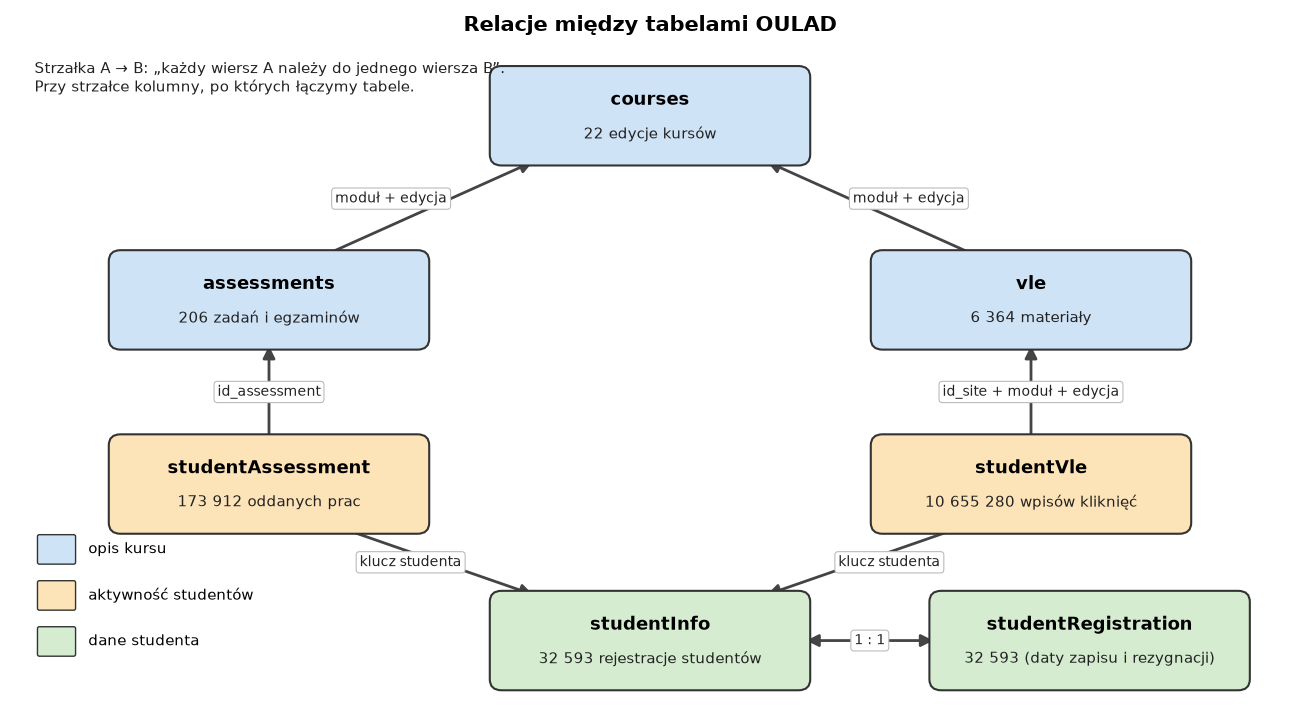

In [10]:
# SCHEMAT RELACJI MIĘDZY TABELAMI OULAD
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 7.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 7.2); ax.axis("off")

# kolory: opis kursu / aktywność studentów / dane studenta
C_KURS, C_AKT, C_STUD = "#cfe3f7", "#fde3b8", "#d5ecd0"
W, H = 3.2, 1.0

def box(cx, cy, name, desc, color):
    ax.add_patch(FancyBboxPatch((cx - W/2, cy - H/2), W, H, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=color, ec="#333333", lw=1.5, zorder=3))
    ax.text(cx, cy + 0.17, name, ha="center", va="center", fontsize=13, fontweight="bold", zorder=4)
    ax.text(cx, cy - 0.2, desc, ha="center", va="center", fontsize=10.5, color="#222222", zorder=4)

def arrow(p1, p2, label=None, lx=0, ly=0, both=False):
    style = "<|-|>" if both else "-|>"
    ax.annotate("", xy=p2, xytext=p1, zorder=2,
                arrowprops=dict(arrowstyle=style, lw=2, color="#444444", shrinkA=0, shrinkB=0, mutation_scale=18))
    if label:
        mx, my = (p1[0] + p2[0]) / 2 + lx, (p1[1] + p2[1]) / 2 + ly
        ax.text(mx, my, label, ha="center", va="center", fontsize=10, color="#222222", zorder=5,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#bbbbbb", lw=0.8))

# pozycje tabel
pos_courses = (6.5, 6.4)
pos_assess, pos_vle = (2.6, 4.4), (10.4, 4.4)
pos_sassess, pos_svle = (2.6, 2.4), (10.4, 2.4)
pos_sinfo, pos_sreg = (6.5, 0.7), (11.0, 0.7)

box(*pos_courses, "courses", "22 edycje kursów", C_KURS)
box(*pos_assess, "assessments", "206 zadań i egzaminów", C_KURS)
box(*pos_vle, "vle", "6 364 materiały", C_KURS)
box(*pos_sassess, "studentAssessment", "173 912 oddanych prac", C_AKT)
box(*pos_svle, "studentVle", "10 655 280 wpisów kliknięć", C_AKT)
box(*pos_sinfo, "studentInfo", "32 593 rejestracje studentów", C_STUD)
box(*pos_sreg, "studentRegistration", "32 593 (daty zapisu i rezygnacji)", C_STUD)

# strzałki: „należy do”, z kolumnami łączenia
arrow((pos_sassess[0], pos_sassess[1] + H/2), (pos_assess[0], pos_assess[1] - H/2), "id_assessment")
arrow((pos_svle[0], pos_svle[1] + H/2), (pos_vle[0], pos_vle[1] - H/2), "id_site + moduł + edycja")
arrow((pos_assess[0] + 0.6, pos_assess[1] + H/2), (pos_courses[0] - 1.2, pos_courses[1] - H/2), "moduł + edycja", lx=-0.4, ly=0.1)
arrow((pos_vle[0] - 0.6, pos_vle[1] + H/2), (pos_courses[0] + 1.2, pos_courses[1] - H/2), "moduł + edycja", lx=0.4, ly=0.1)
arrow((pos_sassess[0] + 0.8, pos_sassess[1] - H/2), (pos_sinfo[0] - 1.2, pos_sinfo[1] + H/2), "klucz studenta", lx=-0.3)
arrow((pos_svle[0] - 0.8, pos_svle[1] - H/2), (pos_sinfo[0] + 1.2, pos_sinfo[1] + H/2), "klucz studenta", lx=0.3)
arrow((pos_sinfo[0] + W/2, pos_sinfo[1]), (pos_sreg[0] - W/2, pos_sreg[1]), "1 : 1", both=True)

# legenda
ax.text(0.2, 7.0, "Strzałka A → B: „każdy wiersz A należy do jednego wiersza B”.\nPrzy strzałce kolumny, po których łączymy tabele.",
        fontsize=10.5, va="top", color="#222222")
for i, (c, t) in enumerate([(C_KURS, "opis kursu"), (C_AKT, "aktywność studentów"), (C_STUD, "dane studenta")]):
    ax.add_patch(FancyBboxPatch((0.25, 1.55 - i*0.5), 0.35, 0.28, boxstyle="round,pad=0.02", fc=c, ec="#333333", lw=1))
    ax.text(0.75, 1.69 - i*0.5, t, va="center", fontsize=10.5)

plt.title("Relacje między tabelami OULAD", fontsize=15, fontweight="bold", pad=8)
plt.tight_layout()
plt.show()

**Jak to rozumieć:** każda tabela „należy do” tabeli, na którą wskazuje strzałka. Na przykład każde kliknięcie z `studentVle` dotyczy jednego materiału z `vle` i jednej rejestracji ze `studentInfo`, a w jeden materiał lub jedną rejestrację klikano wiele razy.

| Tabela | Należy do | Łączymy po | Jak to rozumieć |
|---|---|---|---|
| `studentInfo` i `studentRegistration` | (są parą) | klucz studenta | Dwie części „karty rejestracji”: w jednej dane osobowe i wynik, w drugiej daty zapisu i rezygnacji. Każda rejestracja ma po jednym wierszu w obu tabelach (po 32 593). |
| `studentVle` | `studentInfo` | klucz studenta | Każde kliknięcie ma jednego studenta na kursie, a jeden student ma ich wiele (średnio ok. 365). |
| `studentVle` | `vle` | `id_site` + moduł + edycja | Każde kliknięcie dotyczy jednego materiału, a w jeden materiał klikano wiele razy (średnio ok. 1 700). |
| `studentAssessment` | `assessments` | `id_assessment` | Każda oddana praca dotyczy jednego zadania, a to samo zadanie oddaje wiele osób (średnio ok. 925). |
| `studentAssessment` | `studentInfo` | `id_student` (moduł i edycja przez `assessments`) | Każda oddana praca należy do jednego studenta na kursie, a on oddaje ich wiele (średnio ok. 6,7). |
| `assessments` | `courses` | moduł + edycja | Każde zadanie należy do jednej edycji kursu, a edycja ma ich wiele (średnio ok. 9,4). |
| `vle` | `courses` | moduł + edycja | Każdy materiał należy do jednej edycji kursu, a edycja ma ich wiele (średnio ok. 289). |

**Dlaczego to ważne dla projektu:** dzięki tym połączeniom do każdej rejestracji studenta możemy dołączyć wszystkie jego kliknięcia i oceny. To podstawa budowy sekwencji dla LSTM. Podział na zbiór uczący i testowy robimy po `id_student`, bo jeden student może mieć kilka rejestracji.

Tabela `studentAssessment` nie ma kolumn modułu i edycji, więc pełny klucz studenta trzeba do niej dołączyć przez `assessments`.

In [ ]:
# podgląd każdej tabeli: wymiary, 5 pierwszych wierszy, typy kolumn
for name, df in dfs.items():
    print("=" * 80)
    print(name, df.shape)
    display(df.head(5))
    df.info()

In [ ]:
# unikalne wartości zmiennych kategorialnych (liczność każdej kategorii, razem z brakami)
for col in ["gender", "region", "highest_education", "imd_band", "age_band", "disability", "final_result"]:
    print(f"--- {col} ---")
    print(studentInfo[col].value_counts(dropna=False).to_string())
    print()
print("--- assessment_type ---");  print(assessments["assessment_type"].value_counts().to_string())
print("\n--- activity_type (vle) ---"); print(vle["activity_type"].value_counts().to_string())

In [ ]:
# statystyki opisowe zmiennych liczbowych (min, max, średnia, kwartyle)
display(studentVle[["date", "sum_click"]].describe())
display(studentAssessment[["date_submitted", "score"]].describe())
display(studentRegistration[["date_registration", "date_unregistration"]].describe())
display(courses)

**Wnioski z sekcji 4**

**1. Struktura demograficzna** (odsetki liczone dla rejestracji, nie dla unikalnych osób)

| Cecha | Wynik |
|---|---|
| Płeć | mężczyźni 54,84%, kobiety 45,16% |
| Wiek | 0–35 lat: 70,40%; 35–55 lat: 28,94%; `55<=`: 0,66% |
| Niepełnosprawność | zgłasza 9,71% rejestracji |

Zbiór opisuje głównie młodych dorosłych, co ogranicza możliwość uogólniania wyników na starsze grupy wiekowe.

**2. Rzadkie kategorie**

Zmienne demograficzne w `studentInfo` są kategorialne i w większości dobrze obsadzone. Wyjątkiem są klasy o bardzo niskiej liczebności:
* `age_band` = `55<=`: 216 rejestracji (0,66%),
* `highest_education` = `No Formal quals`: 347 (1,06%),
* `highest_education` = `Post Graduate Qualification`: 313 (0,96%).

Tak małe liczebności mogą utrudniać stabilne szacowanie efektów tych kategorii w modelach predykcyjnych.

**3. Jakość kodowania `imd_band`**

Kategoria `10-20` jest zapisana bez znaku `%`, inaczej niż pozostałe przedziały (np. `20-30%`), więc zapis trzeba ujednolicić przed kodowaniem zmiennej. Zmienna ma też 1 111 braków (3,41%).

**4. Rozkład `sum_click`**

Rozkład jest silnie prawoskośny: mediana 2, średnia ok. 3,7, maksimum 6 977. Nieliczne wartości skrajne mogą mocno zniekształcać sumy dzienne, dlatego warto rozważyć transformację logarytmiczną lub ograniczenie wartości odstających.

**5. Zakresy czasu**

| Zmienna | Zakres (dni od startu kursu) | Uwaga |
|---|---|---|
| `studentVle.date` | −25 … 269 | 6,47% rekordów pochodzi sprzed startu kursu |
| `studentRegistration.date_unregistration` | −365 … 444 | 2 678 dat przed startem, 1 po końcu edycji (5c2) |
| `studentAssessment.date_submitted` | −11 … 608 | 2 057 przed startem (1,18%), 85 po końcu edycji (0,05%) (5c3) |
| `courses.module_presentation_length` | 234 … 269 | długość edycji, punkt odniesienia |

Oś czasu edycji trwa od dnia 0 do 234–269. Wyrejestrowania poza nią sprawdzono w 5c2; daty oddania prac (`date_submitted`) w 5c3.

**6. Oceny (`score`)**

Wartości mieszczą się w przedziale 0–100 (średnia ok. 75,8; mediana 80), co jest zgodne z oczekiwaną skalą ocen.

## 5. Potencjalne problemy jakościowe

Sprawdzamy kolejno: (a) braki danych, (b) duplikaty i integralność kluczy, (c) spójność czasową i etykietę Y, (d) nierównowagę klas, (e) wstępną wizualizację.

In [ ]:
# (a) BRAKI DANYCH: liczba i procent pustych wartości w każdej kolumnie każdej tabeli
# Is_Null: 0 = kolumna kompletna, 1 = są braki; Is_Categorical: 1 = kolumna tekstowa
rows = []
for name, df in dfs.items():
    for col in df.columns:
        n = int(df[col].isnull().sum())
        rows.append({"Tabela": name, "Kolumna": col, "Is_Null": int(n > 0),
                     "Is_Categorical": int(df[col].dtype == "object"),
                     "Braki": n, "Braki_%": round(100 * n / len(df), 2)})
overview = pd.DataFrame(rows)

print("Kolumny z brakami:")
display(overview[overview["Braki"] > 0].reset_index(drop=True))

**Interpretacja (a) – braki danych**

Braki występują w siedmiu kolumnach, ale mają różny charakter. Tylko część z nich wymaga uzupełnienia.

| Kolumna | Braki | Charakter braku | Decyzja |
|---|---|---|---|
| `imd_band` | 1 111 (3,41%) | brak informacji | osobna kategoria „brak” |
| `date_registration` | 45 (0,14%) | brak informacji, znikomy | pominąć lub imputować |
| `score` | 173 (0,10%) | brak informacji, znikomy | pominąć lub imputować |
| `assessments.date` | 11 (5,34%) | zadania bez terminu | sprawdzić typ zadań (5c2) |
| `date_unregistration` | 22 521 (69,10%) | **nie jest to błąd**: brak daty = brak formalnej rezygnacji | nie uzupełniać; z tej kolumny powstaje etykieta Y |
| `vle.week_from`, `vle.week_to` | 5 243 (82,39%) | materiał prawdopodobnie bez przypisanego tygodnia | nie używać jako cech |

**Wniosek:** rzeczywiste braki są niewielkie (w żadnej kolumnie nie przekraczają 5,34%). Kolumny z największym odsetkiem braków (`date_unregistration`, `week_from`, `week_to`) mają własne uzasadnienie i nie wymagają uzupełniania.

In [ ]:
# (b) DUPLIKATY I INTEGRALNOŚĆ KLUCZY
# ile kluczy z tabeli podrzędnej nie ma pary w nadrzędnej; oczekiwane: 0
def orphans(child, parent, on):
    c = child[on].drop_duplicates()
    p = parent[on].drop_duplicates()
    m = c.merge(p, on=on, how="left", indicator=True)   # left_only = brak pary
    return int((m["_merge"] == "left_only").sum()), len(c)

# studentAssessment nie ma kolumn moduł/edycja, więc dołączamy je przez assessments,
# żeby sprawdzić pełny klucz studenta (a nie samo id_student)
sa = studentAssessment.merge(assessments[["id_assessment", "code_module", "code_presentation"]],
                             on="id_assessment", how="left")

tests = [
    ("studentVle → studentInfo",          studentVle,          studentInfo,         key),
    ("studentVle → vle",                  studentVle,          vle,                 ["id_site", "code_module", "code_presentation"]),
    ("studentInfo → studentRegistration", studentInfo,         studentRegistration, key),
    ("studentRegistration → studentInfo", studentRegistration, studentInfo,         key),
    ("studentAssessment → assessments",   studentAssessment,   assessments,         ["id_assessment"]),
    ("assessments → courses",             assessments,         courses,             ["code_module", "code_presentation"]),
    ("vle → courses",                     vle,                 courses,             ["code_module", "code_presentation"]),
    ("studentAssessment → studentInfo",   sa,                  studentInfo,         key),
]
rows = []
for name, ch, pa, on in tests:
    o, n = orphans(ch, pa, on)
    rows.append([name, n, o])
display(pd.DataFrame(rows, columns=["Relacja", "Unikalnych kluczy (podrzędna)", "Bez pary w nadrzędnej"]))

# duplikaty kluczy
print("Duplikaty klucza w studentInfo:        ", int(studentInfo.duplicated(key).sum()))
print("Duplikaty klucza w studentRegistration:", int(studentRegistration.duplicated(key).sum()))
dup_vle = int(studentVle.duplicated(key + ["id_site", "date"]).sum())
print(f"Duplikaty (student, materiał, dzień) w studentVle: {dup_vle} ({100 * dup_vle / len(studentVle):.2f}% wierszy)")

**Interpretacja (b) – duplikaty i integralność kluczy**

**Integralność relacji: bez zastrzeżeń.** W żadnej z 8 sprawdzanych relacji nie ma kluczy bez pary w tabeli nadrzędnej, a klucze w `studentInfo` i `studentRegistration` są unikalne. Tabele można bezpiecznie łączyć.

**Główny problem: duplikaty w `studentVle`.**
* 2 195 960 wierszy (20,61% z 10 655 280) powtarza kombinację student × materiał × dzień.
* Wiersz tej tabeli nie jest więc unikalną obserwacją.
* Przy agregacji do poziomu student–dzień trzeba **sumować `sum_click`**, a nie usuwać duplikaty.

**Rejestracje bez aktywności.** W `studentVle` występuje 29 228 z 32 593 kluczy rejestracji, więc **3 365 rejestracji (10,32%)** nie ma ani jednego zapisu aktywności. Dla modelu LSTM oznaczają one puste sekwencje (rozbicie według wyniku końcowego w komórce 5c2).

In [ ]:
# (c) SPÓJNOŚĆ CZASOWA I ETYKIETA Y
print("studentVle: zakres date =", studentVle["date"].min(), "…", studentVle["date"].max())
print("studentVle: wiersze z date < 0 =", int((studentVle["date"] < 0).sum()),
      f"({100 * (studentVle['date'] < 0).mean():.2f}%)")
print("date_registration < 0:   ", int((studentRegistration["date_registration"] < 0).sum()))
print("date_unregistration < 0: ", int((studentRegistration["date_unregistration"] < 0).sum()))

# czy final_result = Withdrawn zgadza się z obecnością daty wyrejestrowania
reg = studentInfo.merge(studentRegistration, on=key, how="outer")
print("\nfinal_result × czy jest date_unregistration:")
display(pd.crosstab(reg["final_result"], reg["date_unregistration"].notna(), margins=True)
          .rename(columns={False: "brak daty", True: "jest data"}))

# aktywność PO dacie wyrejestrowania
last_act = studentVle.groupby(key)["date"].max().rename("last_activity").reset_index()
chk = studentRegistration.dropna(subset=["date_unregistration"]).merge(last_act, on=key, how="left")
after = chk[chk["last_activity"] > chk["date_unregistration"]]
print(f"Rezygnujący z aktywnością po wyrejestrowaniu: {len(after)} z {len(chk)} ({100*len(after)/len(chk):.2f}%)")

# aktywność PRZED datą rejestracji
first_act = studentVle.groupby(key)["date"].min().rename("first_activity").reset_index()
chk2 = studentRegistration.dropna(subset=["date_registration"]).merge(first_act, on=key, how="left")
before = chk2[chk2["first_activity"] < chk2["date_registration"]]
print(f"Aktywność przed datą rejestracji: {len(before)} z {len(chk2)} ({100*len(before)/len(chk2):.2f}%)")

**Interpretacja (c) – spójność czasowa i etykieta Y**

**Oś czasu**
* 688 988 rekordów `studentVle` (6,47%) pochodzi sprzed startu kursu (`date` < 0, od dnia −25). Trzeba zdecydować, czy sekwencja zaczyna się w dniu 0, czy od pierwszej aktywności.
* Ujemna `date_registration` (32 312 z 32 548) jest normalna, bo zapisy trwają przed startem kursu.
* Aktywności przed datą rejestracji nie ma (0 przypadków).

**Etykieta Y (rezygnacja)**

| Kontrola | Wynik | Konsekwencja |
|---|---|---|
| `Withdrawn` z datą wyrejestrowania | 10 063 z 10 156 (99,08%) | etykieta w zdecydowanej większości spójna |
| `Withdrawn` bez daty | 93 | nie da się ustalić dnia rezygnacji |
| `Fail` z datą wyrejestrowania | 9 | razem 102 niespójne rekordy (0,31%) |
| Ujemne daty wyrejestrowania | 2 678 (26,59% z 10 072) | rezygnacja przed startem, brak okien do przewidywania |
| Aktywność po dacie wyrejestrowania | 1 279 (12,70%); dla dat ≥ 0: 1 152 z 7 394 (15,58%), patrz 5c3 | data nie zawsze kończy aktywność |

**Wniosek:** etykietę Y wyznaczamy z `date_unregistration`, wykluczamy daty ujemne oraz 93 rejestracje `Withdrawn` bez daty, a sekwencję obcinamy w dniu wyrejestrowania.

In [ ]:
# (c2) DODATKOWE KONTROLE (uzupełnienie punktu c)

# 1) rejestracje bez jakiejkolwiek aktywności w VLE (last_act z komórki powyżej)
reg_act = studentInfo.merge(last_act, on=key, how="left")
no_act = reg_act["last_activity"].isna()
print(f"Rejestracje bez żadnej aktywności w VLE: {int(no_act.sum())} z {len(reg_act)} ({100 * no_act.mean():.2f}%)")
display(pd.crosstab(reg_act["final_result"], no_act, margins=True)
          .rename(columns={False: "ma aktywność", True: "brak aktywności"}))

# 2) wyrejestrowania poza osią czasu kursu
creg = studentRegistration.merge(courses, on=["code_module", "code_presentation"], how="left")
unreg = creg.dropna(subset=["date_unregistration"])
print("\nWyrejestrowania PO końcu edycji (date_unregistration > module_presentation_length):",
      int((unreg["date_unregistration"] > unreg["module_presentation_length"]).sum()))
print("Wyrejestrowania PRZED startem kursu (date_unregistration < 0):",
      int((unreg["date_unregistration"] < 0).sum()))

# 3) jakiego typu są zadania bez terminu (assessments.date = NaN)
print("\nZadania bez daty wg typu:")
print(assessments.loc[assessments["date"].isna(), "assessment_type"].value_counts().to_string())

# 4) orientacyjna skala nierównowagi etykiety Y na poziomie okien
#    mianownik: dni studenta = suma długości edycji po wszystkich rejestracjach (górne oszacowanie),
#    licznik: maks. liczba okien pozytywnych = 7 × liczba wyrejestrowań
student_days = int(creg["module_presentation_length"].sum())
print(f"\nDni studenta (rejestracje × długość edycji): {student_days}")
print(f"Maks. okien pozytywnych: {7 * n_unreg}  →  ok. {100 * 7 * n_unreg / student_days:.2f}% wszystkich dni")

**Interpretacja (c2) – dodatkowe kontrole**

**1. Rejestracje bez żadnej aktywności w VLE: 3 365 z 32 593 (10,32%)**

| Wynik końcowy | Bez aktywności | Udział w grupie | Udział w 3 365 |
|---|---|---|---|
| `Withdrawn` | 2 988 z 10 156 | 29,42% | 88,80% |
| `Fail` | 374 z 7 052 | 5,30% | 11,11% |
| `Pass` | 3 z 12 361 | 0,02% | 0,09% |
| `Distinction` | 0 z 3 024 | 0% | 0% |

Brak aktywności dotyczy niemal wyłącznie osób, które zrezygnowały lub nie zaliczyły kursu. Prawie 3 na 10 rezygnujących nigdy nie kliknęło w żaden materiał. Dla LSTM są to puste sekwencje, więc trzeba je wykluczyć lub oznaczyć osobno. Wykluczenie usunie jednak głównie rejestracje `Withdrawn`, dlatego warto sprawdzić, ilu z nich ma datę wyrejestrowania ≥ 0, bo tylko takie byłyby realną stratą próbek pozytywnych.

**2. Wyrejestrowania poza osią czasu kursu**
* **Przed startem** (`date_unregistration` < 0): 2 678. To największa grupa, dla której nie ma sensownych okien do przewidywania.
* **Po końcu edycji** (`date_unregistration` > `module_presentation_length`): tylko 1 przypadek, więc maksimum 444 dni z sekcji 4 to pojedyncza wartość odstająca, a nie wzorzec.
* Daty oddania prac (`date_submitted`, maks. 608) nie były w tej komórce sprawdzane (patrz 5c3).

**3. Zadania bez terminu (`assessments.date`)**

Wszystkie 11 brakujących dat dotyczy zadań typu `Exam` (11 z 24 egzaminów). Brak nie jest więc przypadkowy: egzamin nie ma terminu w trakcie edycji. Zgodnie z dokumentacją zbioru brak daty egzaminu oznacza koniec ostatniego tygodnia edycji, więc jako datę można przyjąć `module_presentation_length`.

**4. Skala nierównowagi etykiety Y na poziomie okien**
* Dni studenta (rejestracje × długość edycji): 8 344 138.
* Maksymalna liczba okien pozytywnych: 70 504, czyli **ok. 0,84%** wszystkich dni (oszacowanie orientacyjne: licznik i mianownik liczone są dla całej edycji, a nie tylko dla dni, w których student był aktywnym uczestnikiem).
* Klasa pozytywna jest więc skrajnie rzadka. Model przewidujący zawsze „brak rezygnacji” miałby ok. 99% Accuracy, więc potrzebne są PR-AUC, recall i F1 oraz wagi klas lub undersampling.

**Wniosek:** wykluczamy lub osobno oznaczamy 3 365 rejestracji bez aktywności, odrzucamy 2 678 rezygnacji sprzed startu, a egzaminom bez daty przypisujemy koniec edycji. Skala nierównowagi na poziomie okien to rząd 0,84% (orientacyjnie).

In [ ]:
# (c3) DODATKOWE KONTROLE: daty oddania prac i aktywność po wyrejestrowaniu

# 1) daty oddania prac względem długości edycji
sa_c = (studentAssessment
        .merge(assessments[["id_assessment", "code_module", "code_presentation", "assessment_type", "date"]],
               on="id_assessment", how="left")
        .merge(courses, on=["code_module", "code_presentation"], how="left"))
n_sa = len(sa_c)
print(f"Prace oddane PRZED startem kursu (date_submitted < 0): {int((sa_c['date_submitted'] < 0).sum())}")
late = sa_c[sa_c["date_submitted"] > sa_c["module_presentation_length"]]
print(f"Prace oddane PO końcu edycji: {len(late)} z {n_sa} ({100 * len(late) / n_sa:.2f}%)")
print(late["assessment_type"].value_counts().to_string())

# 2) aktywność po wyrejestrowaniu: ile przypadków zostaje, gdy pominiemy daty ujemne
pos = chk[chk["date_unregistration"] >= 0]
after_pos = after[after["date_unregistration"] >= 0]
print(f"\nAktywność po wyrejestrowaniu (tylko date_unregistration >= 0): {len(after_pos)} z {len(pos)} ({100 * len(after_pos) / len(pos):.2f}%)")

# 3) rejestracje bez aktywności, które mają datę wyrejestrowania >= 0
noact = reg_act.loc[no_act, key].merge(studentRegistration, on=key, how="left")
print(f"Rejestracje bez aktywności z date_unregistration >= 0: {int((noact['date_unregistration'] >= 0).sum())}")

**Interpretacja (c3) – dodatkowe kontrole**

**1. Daty oddania prac (`date_submitted`)**
* Przed startem kursu: 2 057 prac (1,18% ze 173 912), zakres do −11 dni. To prawdopodobnie wczesne oddania, a nie błąd.
* Po końcu edycji: 85 prac (0,05%): 70 CMA, 12 Exam i 3 TMA. Maksimum 608 dni to więc rzadka wartość skrajna, a nie wzorzec.
* **Wniosek:** daty oddania są w zasadzie spójne z osią czasu kursu. Oceny wchodzą do cech od dnia oddania, prace oddane przed startem liczymy od dnia 0, a 85 prac po końcu edycji można pominąć.

**2. Aktywność po wyrejestrowaniu**
* Dla dat wyrejestrowania ≥ 0 aktywność po tej dacie ma 1 152 z 7 394 rejestracji (15,58%). Ujemne daty tłumaczą tylko 127 z 1 279 przypadków z punktu 5c (ok. 10%), więc zjawisko nie jest artefaktem dat ujemnych. Jest nawet częstsze, niż pokazywało 12,70%.
* Data wyrejestrowania jest zdarzeniem formalnym, a nie końcem aktywności: część studentów nadal korzysta z materiałów. Model będzie więc przewidywał formalną rezygnację, a nie zaprzestanie nauki (ograniczenie do zapisania w wnioskach).
* **Reguła:** okna generujemy tylko dla dni T < `date_unregistration`, a aktywności po dacie wyrejestrowania nie wprowadzamy do wejścia modelu.

**3. Rejestracje bez aktywności z datą wyrejestrowania ≥ 0**
* 757 z 3 365 rejestracji bez aktywności ma datę wyrejestrowania ≥ 0, czyli 10,24% z 7 394 rejestracji, które mogą dać okna pozytywne. Pozostałe 2 608 ma datę ujemną albo jej nie ma.
* **Wniosek:** wykluczenie wszystkich 3 365 rejestracji kosztowałoby 757 potencjalnych próbek pozytywnych. To osoby, które zrezygnowały, nie zaczynając kursu, więc sekwencja samych zer może być dla modelu ważnym sygnałem. Decyzję (wykluczyć czy zostawić z zerowymi sekwencjami) podejmiemy przy budowie okien.

In [ ]:
# (d) + (e) NIERÓWNOWAGA KLAS I WSTĘPNE WYKRESY
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) rozkład wyniku końcowego
order = ["Distinction", "Pass", "Fail", "Withdrawn"]
sns.countplot(data=studentInfo, x="final_result", hue="final_result", order=order,
              palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Wynik końcowy (final_result)"); ax[0].set_xlabel(""); ax[0].set_ylabel("Liczba rejestracji")

# 2) w którym dniu kursu studenci się wyrejestrowują
sns.histplot(studentRegistration["date_unregistration"].dropna(), bins=60, color="indianred", ax=ax[1])
ax[1].set_title("Dzień wyrejestrowania"); ax[1].set_xlabel("dzień kursu"); ax[1].set_ylabel("Liczba rejestracji")

# 3) łączna liczba kliknięć w kolejnych dniach kursu
daily = studentVle.groupby("date")["sum_click"].sum()
ax[2].plot(daily.index, daily.values, color="steelblue", lw=0.8)
ax[2].set_title("Łączna liczba kliknięć dziennie"); ax[2].set_xlabel("dzień kursu"); ax[2].set_ylabel("Liczba kliknięć")

plt.tight_layout(); plt.show()

**Interpretacja (d) – nierównowaga klas**

* **Poziom rejestracji:** Pass 37,93%, Withdrawn 31,16%, Fail 21,64%, Distinction 9,28%. Nierównowaga jest umiarkowana.
* **Poziom okien 7-dniowych:** dla etykiety Y jest co najwyżej 70 504 okien pozytywnych (7 × 10 072), a to ok. 0,84% wszystkich dni studentów (szacunek orientacyjny, patrz 5c2). Klasa pozytywna będzie więc bardzo rzadka.
* **Konsekwencja:** Accuracy byłaby myląca, bo model przewidujący zawsze „brak rezygnacji” miałby ok. 99% trafności. Potrzebne są metryki PR-AUC, recall i F1 oraz wagi klas lub undersampling.

**Interpretacja (e) – wstępne wykresy**

* **Dzień wyrejestrowania:** rozkład ma wyraźny pik wokół dnia 0 i potem stopniowo maleje. Wiele rezygnacji przypada tuż przed i tuż po starcie kursu, co zgadza się z dużą liczbą ujemnych dat (sekcja 5c).
* **Łączna liczba kliknięć:** największa aktywność jest na początku (szczyt w okolicy 20. dnia), potem spada z regularnymi wahaniami (prawdopodobnie tygodniowymi). Po ok. 245. dniu aktywność niemal zanika, co odpowiada końcowi typowej edycji.
* **Konsekwencja:** aktywność jest niestacjonarna i zależy od etapu kursu oraz dnia tygodnia, więc cechy modelu powinny to uwzględniać (np. numer dnia kursu, dzień tygodnia).

In [ ]:
# PRZERWY W AKTYWNOŚCI: rezygnujący vs pozostali (prototyp na modułach AAA i BBB, żeby było szybciej)
mods = ["AAA", "BBB"]
sv = studentVle[studentVle["code_module"].isin(mods)]

# unikalne dni aktywności każdego studenta (od dnia 0), posortowane chronologicznie
act = (sv[key + ["date"]].drop_duplicates().query("date >= 0").sort_values(key + ["date"]))
act["gap"] = act.groupby(key)["date"].diff()      # przerwa = różnica między kolejnymi dniami aktywności
max_gap = act.groupby(key)["gap"].max().rename("max_gap").reset_index()

# dołączamy wynik końcowy; student bez aktywności lub z jednym dniem aktywności nie ma żadnej przerwy -> wpisujemy 0
si = studentInfo[studentInfo["code_module"].isin(mods)][key + ["final_result"]]
tmp = si.merge(max_gap, on=key, how="left")
tmp["max_gap"] = tmp["max_gap"].fillna(0)
tmp["grupa"] = np.where(tmp["final_result"] == "Withdrawn", "Withdrawn", "Pozostali")

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=tmp, x="grupa", y="max_gap", hue="grupa", palette="coolwarm", legend=False)
plt.title("Najdłuższa przerwa w aktywności (moduły AAA, BBB)")
plt.ylabel("dni"); plt.xlabel("")
plt.show()
display(tmp.groupby("grupa")["max_gap"].describe())

**Uwaga interpretacyjna:** metryka „najdłuższa przerwa” jest tu myląca. Mediana dla `Withdrawn` wynosi 0, czyli co najmniej połowa rezygnujących ma najwyżej jeden dzień aktywności od dnia 0 (taka sekwencja nie ma żadnej przerwy). Wynik „rezygnujący mają krótsze przerwy” wynika więc prawdopodobnie z tego, że szybko przestają się logować i mają za mało dni, by wykazać długą przerwę. W dalszej analizie lepsze będą cechy typu liczba aktywnych dni oraz liczba dni od ostatniej aktywności.

### Rejestr potencjalnych problemów jakościowych

| # | Problem | Skala | Konsekwencja dla projektu | Proponowane działanie |
|---|---|---|---|---|
| 1 | Braki w danych demograficznych i ocenach | `imd_band` 1 111 (3,41%); `date_registration` 45 (0,14%); `score` 173 (0,10%); `assessments.date` 11 (5,34%) | niewielkie, ale model nie przyjmie NaN | kategoria „brak” dla `imd_band`; pozostałe pominąć lub imputować |
| 2 | Prawie puste kolumny | `vle.week_from` / `week_to`: 82,39% braków | cechy niezdatne do użycia | nie używać |
| 3 | Duplikaty w `studentVle` | 2 195 960 wierszy (20,61%) | podwójne liczenie, jeśli wiersz uznać za obserwację | zsumować `sum_click` do poziomu student–dzień |
| 4 | Rejestracje bez aktywności w VLE | 3 365 (10,32%) | puste sekwencje dla LSTM | wykluczyć lub osobno oznaczyć; 88,80% z nich to `Withdrawn`, a 757 ma datę wyrejestrowania ≥ 0 (5c2, 5c3) |
| 5 | Aktywność przed startem kursu | 688 988 rekordów (6,47%) z `date` < 0 | niejednoznaczny początek osi czasu | ustalić: start w dniu 0 albo dopuścić dni ujemne |
| 6 | Niespójna etykieta rezygnacji | 93 `Withdrawn` bez daty; 9 `Fail` z datą; 2 678 dat ujemnych; 1 279 (12,70%) rezygnujących z aktywnością po wyrejestrowaniu (dla dat ≥ 0: 1 152 z 7 394, 15,58%, 5c3) | niepewna definicja Y | Y z `date_unregistration`; wykluczyć daty ujemne i 93 rejestracje bez daty; obciąć sekwencję w dniu wyrejestrowania |
| 7 | Nierównowaga klas | `Withdrawn` 31,16% rejestracji; na poziomie okien ok. 0,84% (orientacyjnie, 5c2) | model może przewidywać tylko klasę większościową | wagi klas lub undersampling; metryki PR-AUC, recall, F1 zamiast accuracy |
| 8 | Powtórne rejestracje tych samych osób | 3 808 | wyciek danych między zbiorem treningowym a testowym | Group K-Fold po `id_student` |
| 9 | Niespójne etykiety i rzadkie kategorie | `imd_band` „10-20” bez „%”; `55<=` (216), `No Formal quals` (347), `Post Graduate Qualification` (313) | błędne kodowanie, niestabilne szacunki | ujednolicić zapis, połączyć rzadkie kategorie |
| 10 | Skośność i wartości odstające | `sum_click`: mediana 2, średnia ok. 3,7, maks. 6 977 | pojedyncze rekordy dominują sumy | transformacja `log1p` lub obcięcie |
| 11 | Daty poza osią czasu kursu | `date_unregistration`: 2 678 przed startem i 1 po końcu edycji (maks. 444); `date_submitted`: 2 057 przed startem (1,18%), 85 po końcu edycji (0,05%), maks. 608 (5c3) | rezygnacje przed startem nie mają okien do przewidywania; oddania po końcu edycji dotyczą znikomej części prac | wykluczyć rezygnacje przed startem; prace oddane po końcu edycji pominąć w cechach ocen |
| 12 | Ograniczona reprezentatywność i rozdzielczość | jedna uczelnia (kształcenie zdalne), edycje 2013–2014, czas w dniach bez godzin | ograniczona generalizacja wyników | zaznaczyć w wnioskach i ograniczeniach |

## 6. Podsumowanie

Zbiór OULAD jest kompletny, spójny relacyjnie i wystarcza do zbudowania dziennych sekwencji aktywności dla sieci LSTM. Wymaga jednak kilku decyzji przy przygotowaniu danych, głównie przy definicji etykiety rezygnacji i konstrukcji sekwencji.

| Element raportu | Ustalenia |
|---|---|
| **Źródło danych** | OULAD (Kuzilek, Hlosta, Zdrahal, 2017), Open University. Dane wtórne, zanonimizowane, licencja CC BY 4.0. Użyto kopii z Kaggle. |
| **Sposób pozyskania** | Automatyczne pobranie biblioteką `kagglehub` i wczytanie 7 plików CSV do słownika `dfs`. Tabela `studentVle` wczytana z oszczędnymi typami liczbowymi (`int16`, `int32`). |
| **Liczba obserwacji** | 32 593 rejestracje (student × edycja kursu), 28 785 unikalnych studentów, 7 modułów, 22 edycje. Łącznie 10 900 970 wierszy, z czego 97,7% (10 655 280) to logi `studentVle`. |
| **Struktura** | 7 powiązanych tabel, klucz studenta (`code_module`, `code_presentation`, `id_student`), czas jako liczba dni względem startu kursu (bez godzin). Integralność kluczy obcych zachowana: 0 rekordów bez pary w 8 sprawdzonych relacjach. |
| **Wynik końcowy** | Pass 37,93%, Withdrawn 31,16%, Fail 21,64%, Distinction 9,28%. |

**Najważniejsze problemy jakościowe i przyjęte decyzje**

| Problem | Skala | Decyzja |
|---|---|---|
| Duplikaty w `studentVle` | 2 195 960 wierszy (20,61%) | sumować `sum_click` do poziomu student–dzień |
| Rejestracje bez żadnej aktywności | 3 365 (10,32%), z czego 88,80% to `Withdrawn`; 757 ma datę wyrejestrowania ≥ 0 | wykluczyć lub osobno oznaczyć (wykluczenie kosztuje 757 potencjalnych próbek pozytywnych) |
| Niespójna etykieta rezygnacji | 93 `Withdrawn` bez daty, 9 `Fail` z datą, aktywność po wyrejestrowaniu u 1 279 (12,70%), a dla dat ≥ 0 u 1 152 z 7 394 (15,58%) | Y z `date_unregistration`, sekwencję obciąć w dniu wyrejestrowania |
| Rezygnacje przed startem kursu | 2 678 (26,59% dat wyrejestrowania) | wykluczyć, bo nie ma okien do przewidywania |
| Nierównowaga klas | okna pozytywne ok. 0,84% dni (orientacyjnie) | PR-AUC, recall, F1, wagi klas zamiast Accuracy |
| Powtórne rejestracje tych samych osób | 3 808 | Group K-Fold po `id_student`, żeby uniknąć wycieku danych |
| Braki w danych | `imd_band` 3,41%; `week_from` / `week_to` 82,39% | `imd_band`: kategoria „brak”; `week_from` / `week_to` nie używać |
| Aktywność przed startem kursu | 688 988 rekordów (6,47%) | ustalić początek osi czasu (dzień 0 albo dni ujemne) |
| Daty oddania prac poza osią czasu | 2 057 przed startem (1,18%), 85 po końcu edycji (0,05%) | wczesne oddania liczyć od dnia 0, późne pominąć |

**Następny krok:** agregacja `studentVle` do poziomu student–dzień (z sumowaniem duplikatów i rzutowaniem `sum_click` na większy typ liczbowy, bo `int16` przy dodawaniu może się przepełnić), ustalenie reguł dla osi czasu i etykiety Y, budowa okien przesuwnych W ∈ {7, 14, 28} i podział Group K-Fold po `id_student`.